In [23]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool
import pickle
import scipy
from matplotlib.lines import Line2D

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [30]:
with open('pickled/mcmc_0.001_32_40000_2024-09-03_21-04-02.pkl', 'rb') as h:
    mcmc_output = pickle.load(h)

In [41]:
with open('pickled/mcmc_0.001_32_40000_2024-09-04_04-28-57.pkl', 'rb') as k:
    mcmc_output2 = pickle.load(k)

In [44]:
mcmc_output2.shape, mcmc_output.shape

((85312, 2), (85312, 2))

In [48]:
mcmc_output_combined = np.concatenate((mcmc_output, mcmc_output2), axis=0)
mcmc_output_combined.shape

(170624, 2)

(170624, 2)


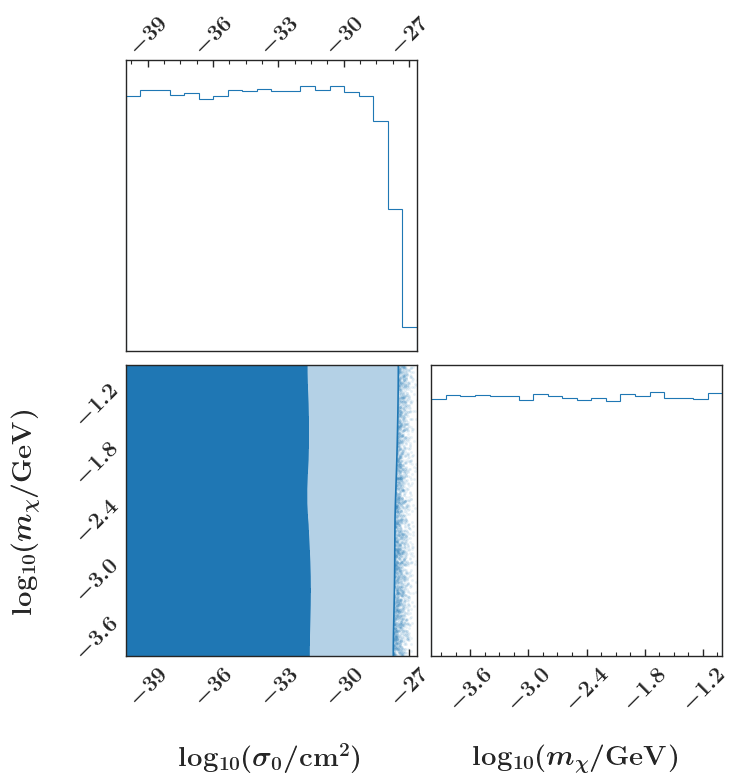

In [178]:
# create corner plot of results
paper_plot()

print(mcmc_output_combined.shape)
figure = plt.figure(figsize=(8, 8))



labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_combined, 
    labels=labels, 
    dpi=450, 
    smooth=3.0, 
    levels=[0.68, 0.95], 
    top_ticks=True, 
    color='#1f77b4',
    fill_contours=True,
    plot_density=True,
    #contourf_kwargs={"alpha": 0.7}, 
    scatter_kws={"alpha": 0}, 
    fig=figure
);


# Access the axes of the corner plot
axes = figure.get_axes()

# Enable minor ticks and customize tick parameters for each subplot
for ax in axes:
    ax.minorticks_on()
    ax.tick_params(which='both', direction='in')

plt.show()
#savefig(fig, 'plots/corner_plot.png', dpi=450)

In [172]:
np.median(mcmc_output_combined[:, 0]), np.median(mcmc_output_combined[:, 1])

(-33.78174641162805, -2.5010686851456514)

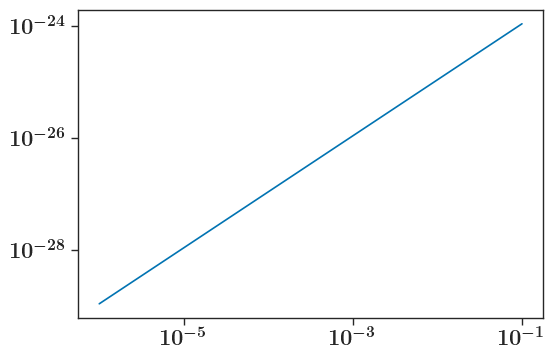

In [164]:
# get prior
# Unpickle the dictionary from the file
with open('data/prior_boundary_points.pkl', 'rb') as f:
    data = pickle.load(f)

# Unpack the dictionary into variables
mchi_values = data['mchi']
s0_max = data['max_s0']

plt.loglog(mchi_values, s0_max)

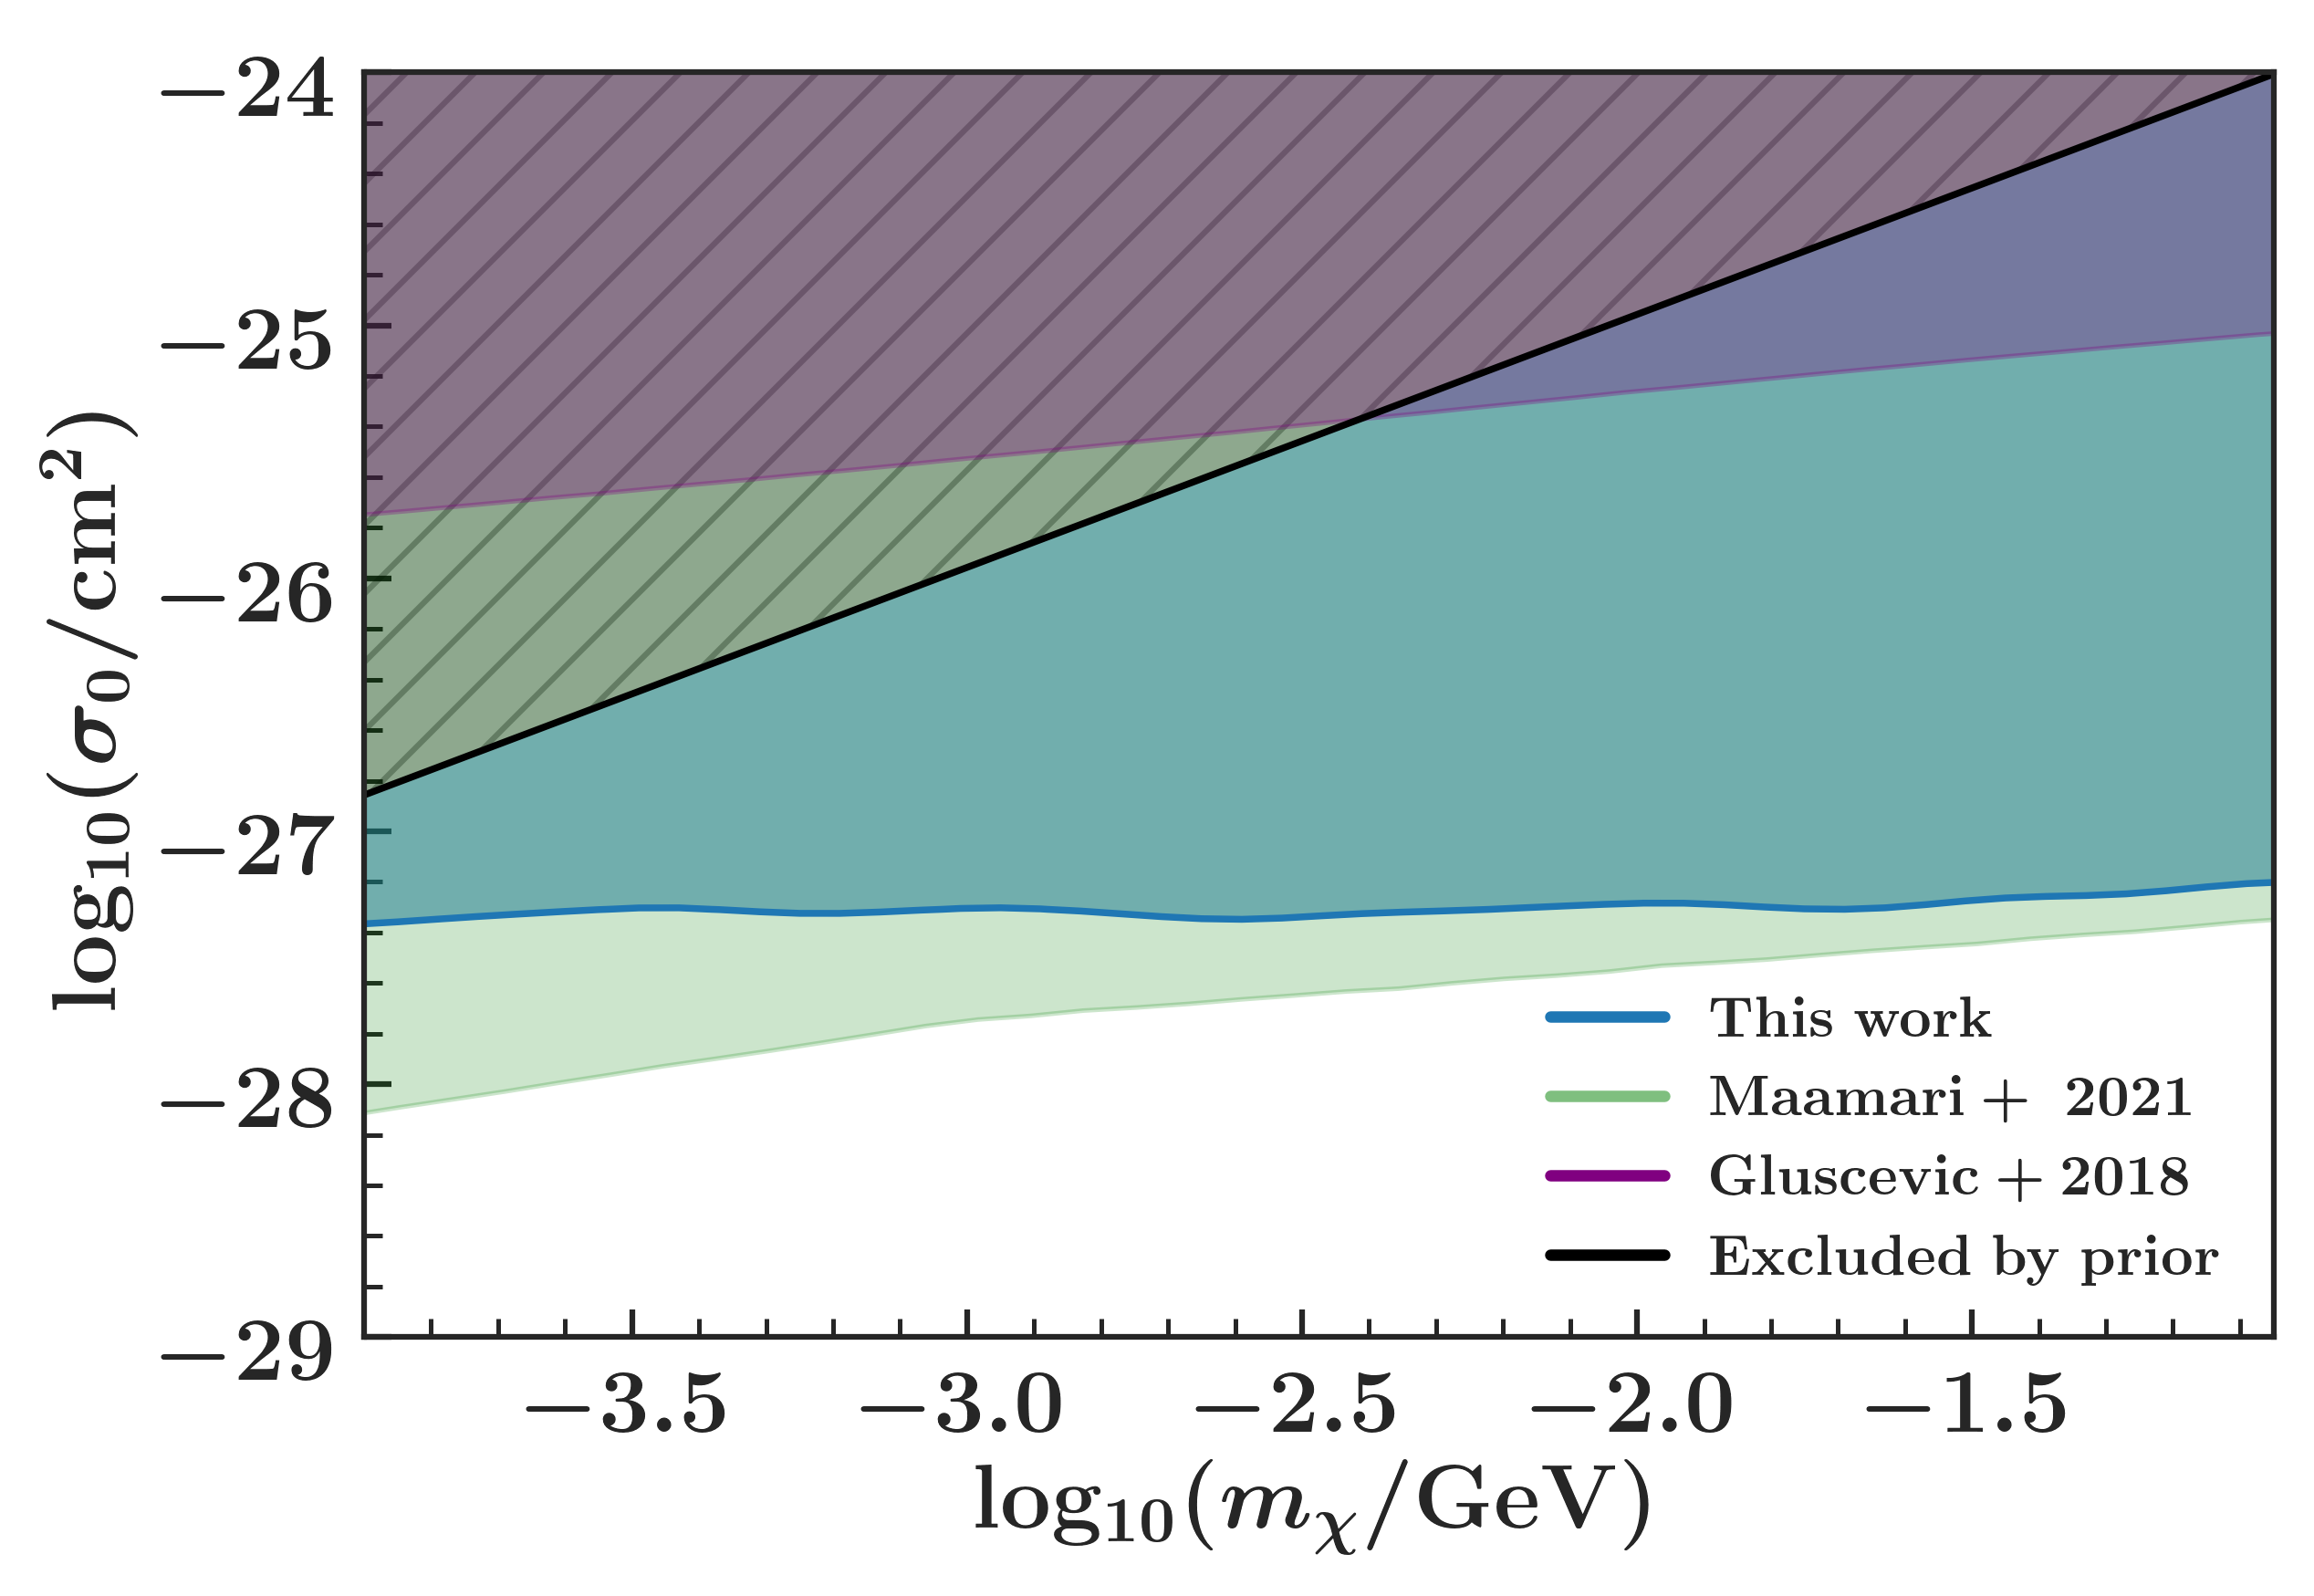

In [171]:
samples_coords = np.array([[x, y] for y, x in mcmc_output_combined])

# Reshape to get a 2D array of samples
x_samples = samples_coords[:,0]
y_samples = samples_coords[:,1]

# Create a 2D histogram
nbins = 50
H, xedges, yedges = np.histogram2d(x_samples, y_samples, bins=nbins, density=True)

# Apply Gaussian smoothing
sigma = 2.0
H_smooth = scipy.ndimage.gaussian_filter(H, sigma=sigma)

# Compute the bin centers
xcenters = (xedges[:-1] + xedges[1:]) / 2
ycenters = (yedges[:-1] + yedges[1:]) / 2

# Create a meshgrid for the centers
X, Y = np.meshgrid(xcenters, ycenters)

# Flatten the smoothed histogram and sort the values
H_smooth_flat = H_smooth.flatten()
H_smooth_sorted = np.sort(H_smooth_flat)

# Calculate the cumulative distribution function (CDF)
cdf = np.cumsum(H_smooth_sorted)
cdf /= cdf[-1]  # Normalize

# Define the percentiles for contour levels
#percentiles = [50, 75, 90, 95]
#levels = np.percentile(H_smooth_sorted, percentiles)

# Find the 95th percentile value
percentile_value = np.percentile(H_smooth, 5)

# Generate the contour plot
plt.figure(dpi=450)#(figsize=(8, 6))
contour = plt.contour(X, Y, H_smooth.T, levels=[percentile_value],colors='#1f77b4')
#plt.colorbar(contour, label='Density')
#plt.contourf(X, Y, H_smooth.T, levels=[0,percentile_value], alpha=0.5,colors='#1f77b4')


path = contour.collections[0].get_paths()[0]
v = path.vertices
x = v[:,0]
y = v[:,1]

#y2=-24
y2 = np.interp(x, np.log10(mchi_values), np.log10(s0_max))
plt.fill_between(x, y, y2, where=(y2 >= y), interpolate=True, color='#1f77b4', alpha=0.5)



#plt.clabel(contour)
handles=[Line2D([0], [0], color='#1f77b4', lw=2, label=f'$\mathrm{{This~work}}$'),
        Line2D([0], [0], color='green', alpha=0.5, lw=2, label=f"$\mathrm{{Maamari+~2021}}$"),
        Line2D([0], [0], color='purple', lw=2, label=f"$\mathrm{{Gluscevic+ 2018}}$"),
        Line2D([0], [0], color='black', lw=2, label=f"$\mathrm{{Excluded~by~prior}}$")]

#plt.xlim(-4, -1)
#plt.ylim(-30, -25.5)

# prior
plt.plot(np.log10(mchi_values), np.log10(s0_max), color='black')
plt.fill_between(
                    np.log10(mchi_values), np.log10(s0_max),
                    y2=1e-26,
                    alpha=0.3, color='black', hatch='//'
                )



import pandas as pd
maamari = pd.read_csv('data/maamari_2021_constraint.csv', header=None)
plt.plot(maamari[0], maamari[1], label=f"$\mathrm{{Maamari+ 2021}}$", color='green')

plt.fill_between(
                    np.log10(maamari[0]), np.log10(maamari[1]),
                    y2=1e-26,
                    alpha=0.2, color='green'
                )


gluscevic = pd.read_csv('data/gluscevic_boddy_2018_velocity_independent.csv', header=None)
plt.plot(gluscevic[0], gluscevic[1], label=f"$\mathrm{{Gluscevic+ 2018}}$", color='green')



plt.fill_between(
                    np.log10(gluscevic[0]), np.log10(gluscevic[1]),
                    y2=1e-26,
                    alpha=0.3, color='purple'
                )



plt.legend(handles=handles, loc='lower right', frameon=False, fontsize=10)
#plt.xlabel(r"$m_{\chi} \mathrm{(GeV)}$")
#plt.ylabel(r"$\sigma_0 (\mathrm{cm}^2)$")
plt.xlabel("DM particle mass (GeV)")
plt.ylabel(r"Interaction cross section (cm$^2$)")





# Customize the plot
#plt.title('95th Percentile Contour Plot')
plt.xlabel(r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$", size=16)
plt.ylabel(r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", size=16)

# Show the plot
plt.minorticks_on()  # Enable minor ticks
plt.tick_params(which='both', direction='in')

plt.xlim(-3.9, 1.05*x_samples.max())
plt.ylim(-29, -24)

#fig=plt.gcf()
#savefig(fig, 'plots/constraints_comparison_entire_space_exclude_region.png', dpi=450)
plt.show()




-27.304462615153508

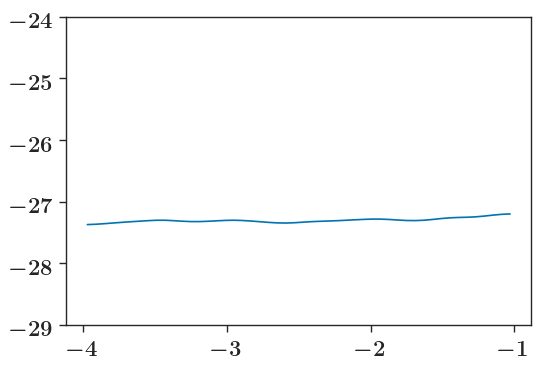

In [177]:
plt.plot(x, y)
plt.ylim(-29, -24)
np.mean(y)

In [150]:
np.log10(u.MeV.to(u.GeV))

-3.0

In [169]:
np.log10(100*u.keV.to(u.GeV))

-4.0

(21328, 2)


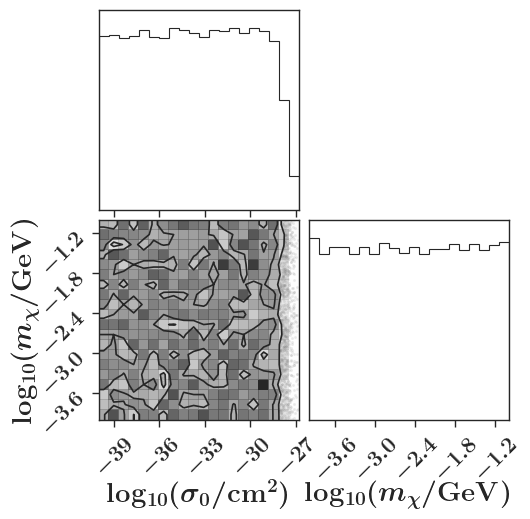

In [10]:
with open('pickled/mcmc_0.001_16_20000_2024-08-15_01-25-20.pkl', 'rb') as f:
    mcmc_output_edd = pickle.load(f)
print(mcmc_output_edd.shape)

labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_edd, labels=labels, dpi=450, levels=[0.68, 0.95]
);

(21328, 2)


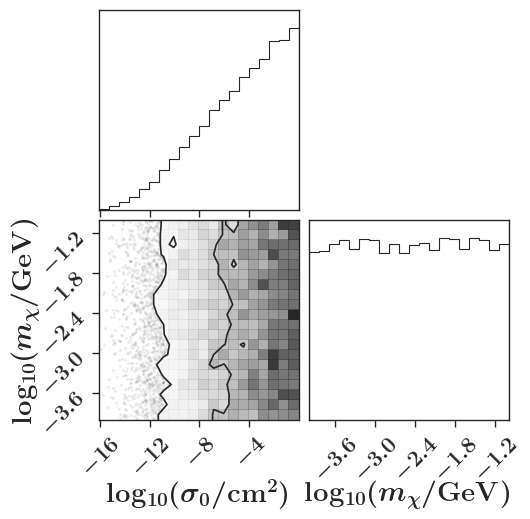

In [11]:
with open('pickled/mcmc_0.001_16_20000_eddington_0.1_2024-06-12_16-24-35.pkl', 'rb') as f:
    mcmc_output_edd_01 = pickle.load(f)
print(mcmc_output_edd_01.shape)

labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_edd_01, labels=labels, dpi=450, levels=[0.68, 0.95]
);

(21328, 2)


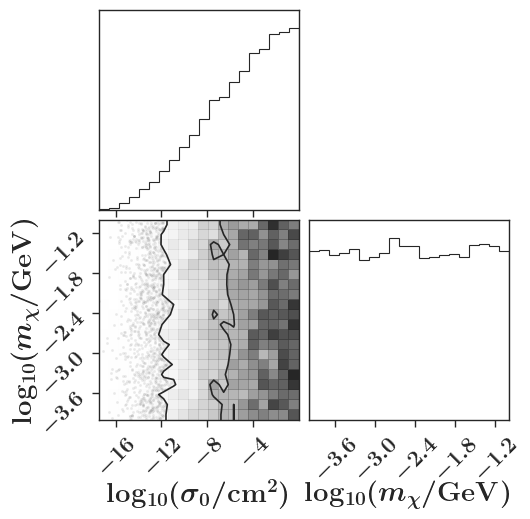

In [40]:
with open('pickled/mcmc_0.001_16_20000_eddington_0.01_2024-06-12_18-36-52.pkl', 'rb') as f:
    mcmc_output_edd_001 = pickle.load(f)
print(mcmc_output_edd_001.shape)

labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_edd_001, labels=labels, dpi=450, levels=[0.68, 0.95]
);

(21328, 2)


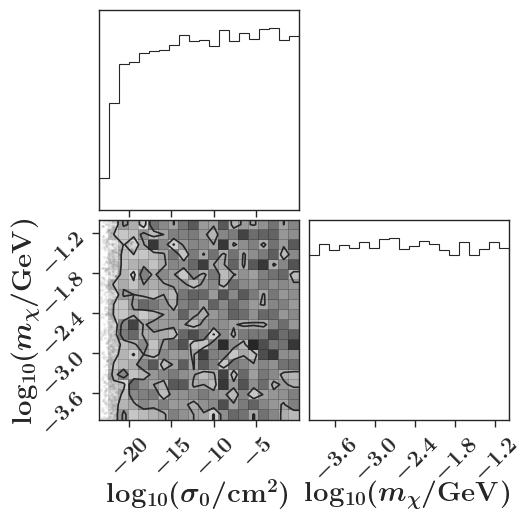

In [42]:


with open('pickled/mcmc_0.001_16_20000_2024-06-12_18-53-01.pkl', 'rb') as f:
    mcmc_output_iq_1 = pickle.load(f)
print(mcmc_output_iq_1.shape)

labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_iq_1, labels=labels, dpi=450, levels=[0.68, 0.95]
);


(21328, 2)


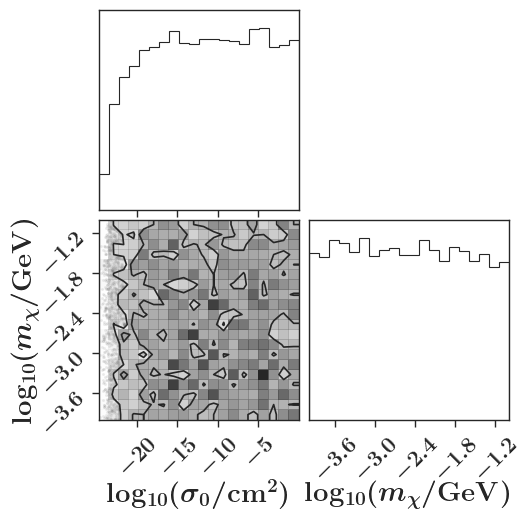

In [45]:

with open('pickled/mcmc_0.001_16_20000_2024-06-12_16-37-35.pkl', 'rb') as f:
    mcmc_output_iq_2 = pickle.load(f)
print(mcmc_output_iq_2.shape)

labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_iq_2, labels=labels, dpi=450, levels=[0.68, 0.95]
);


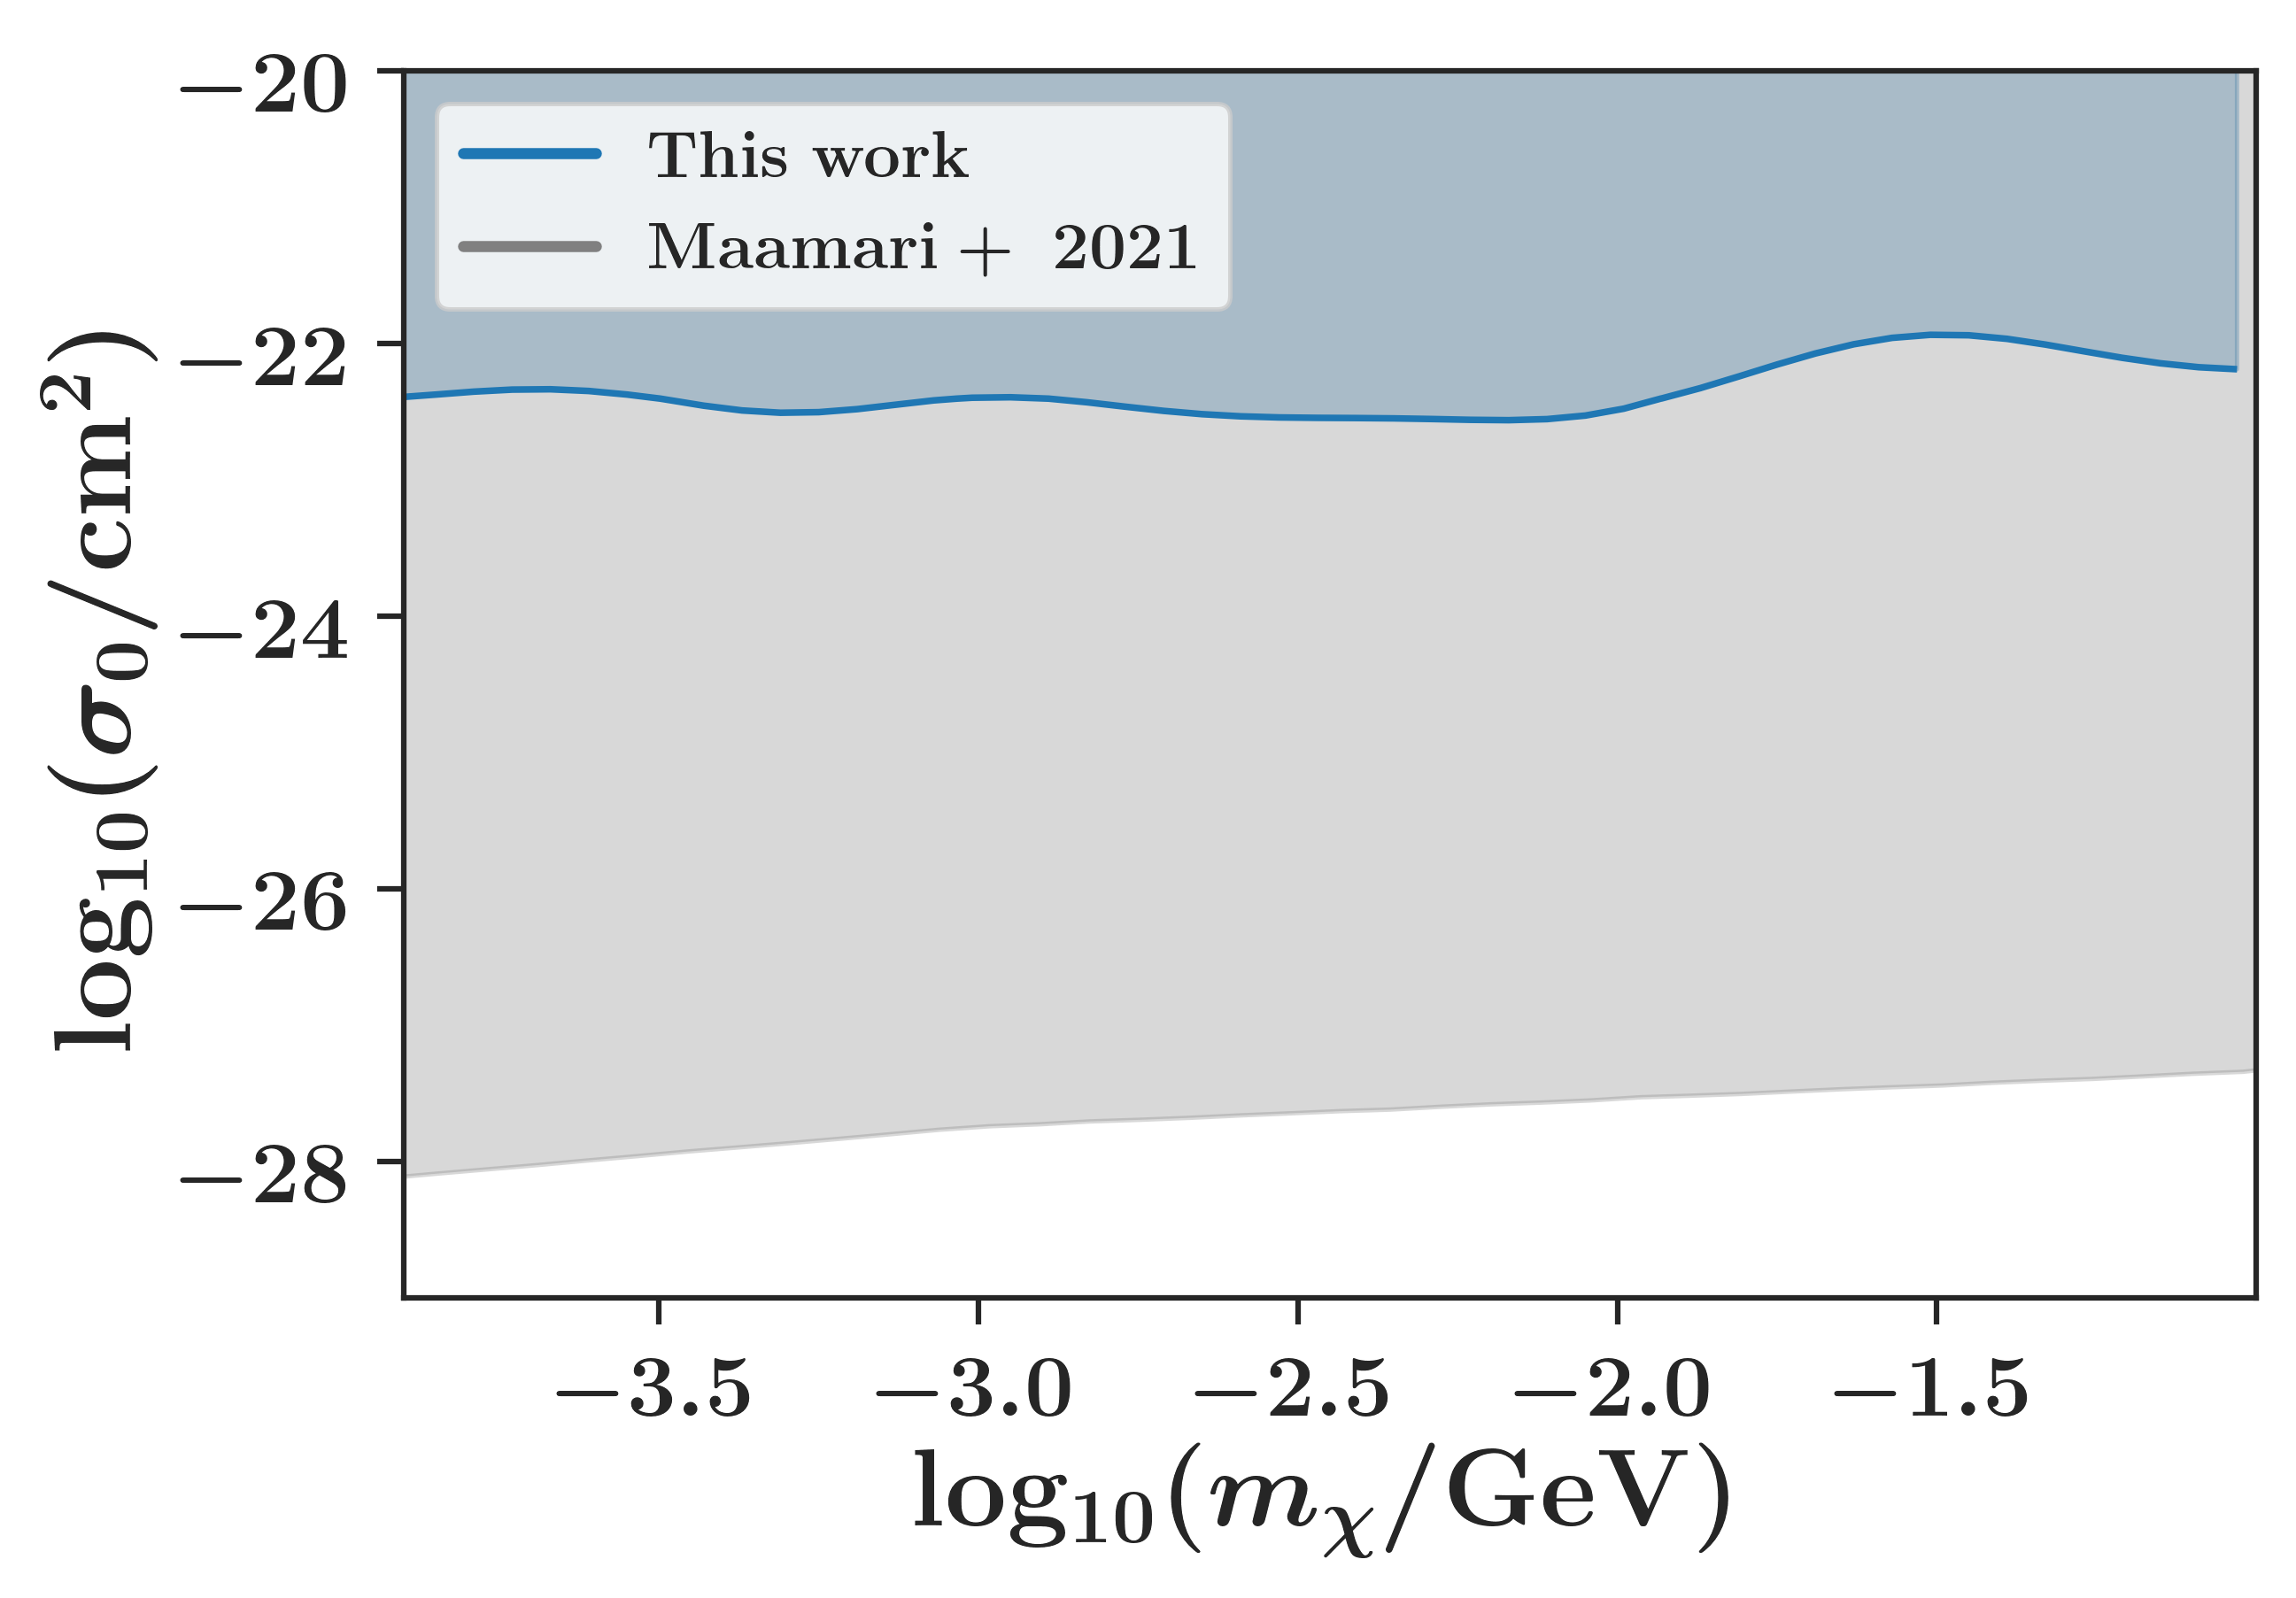

In [70]:
make_contour(mcmc_output_iq_1, -29, -20)

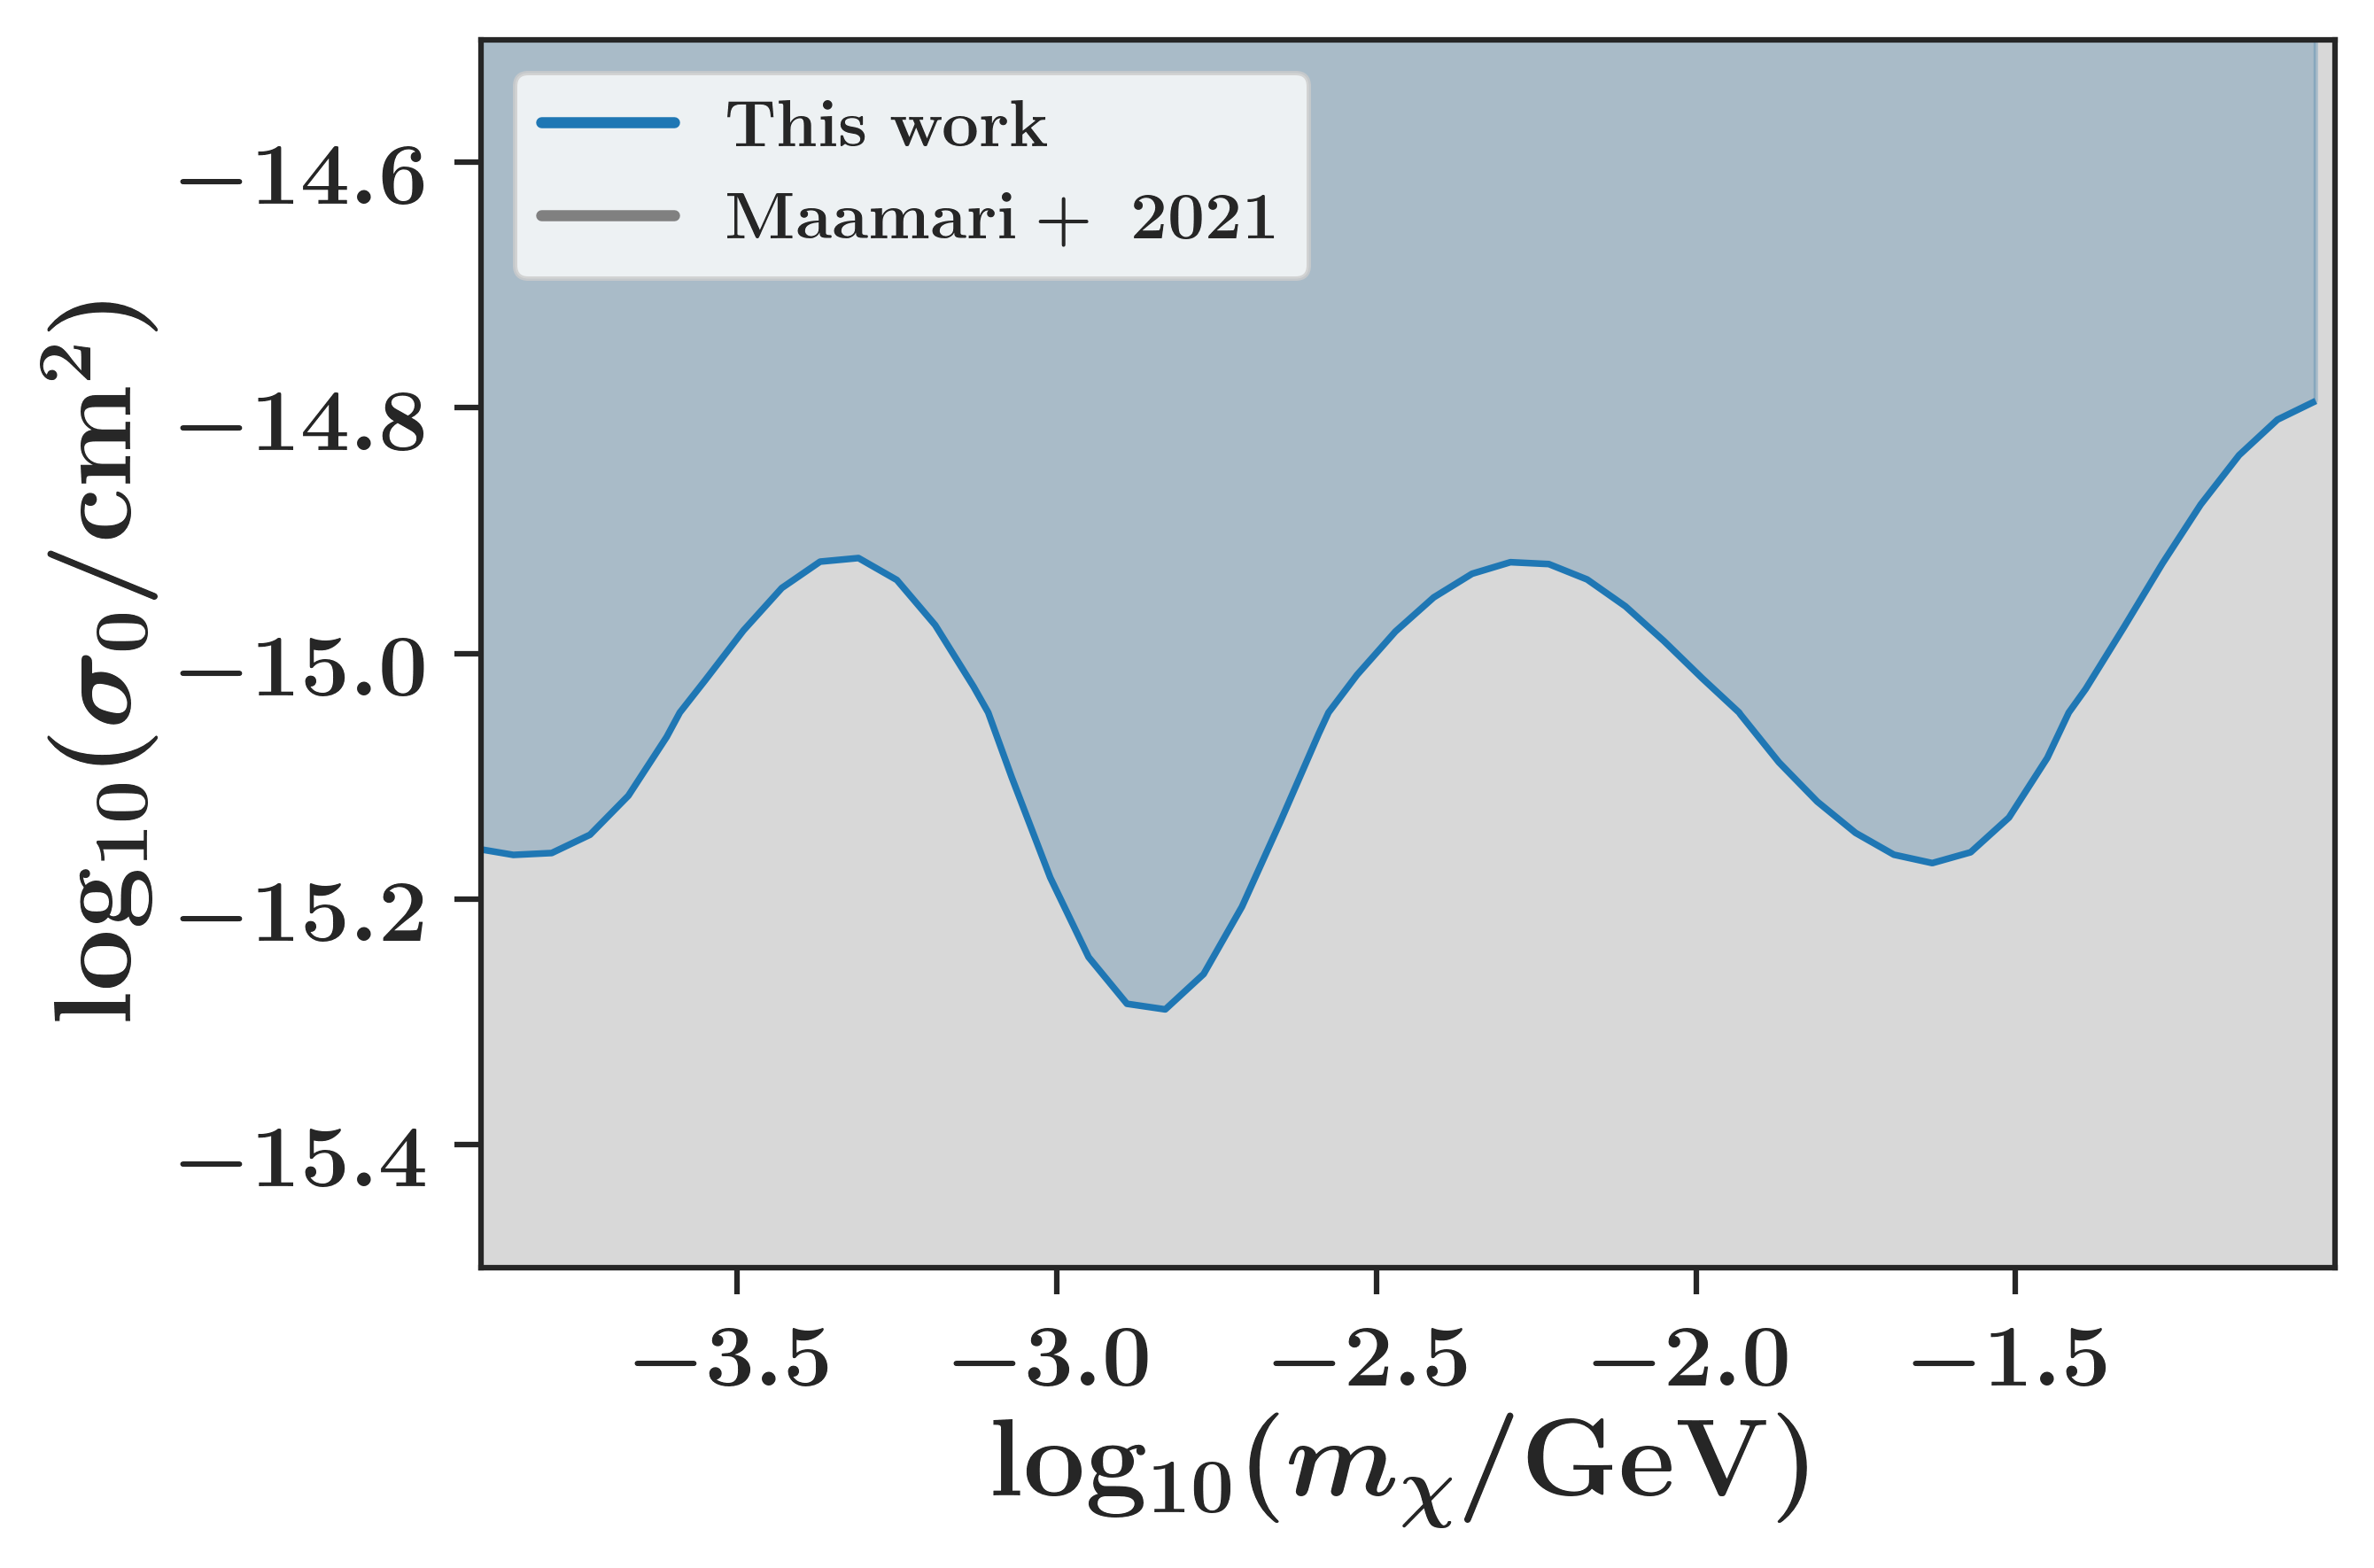

In [66]:
from make_contour_plot import make_contour

make_contour(mcmc_output_edd, -15.5, -14.5)



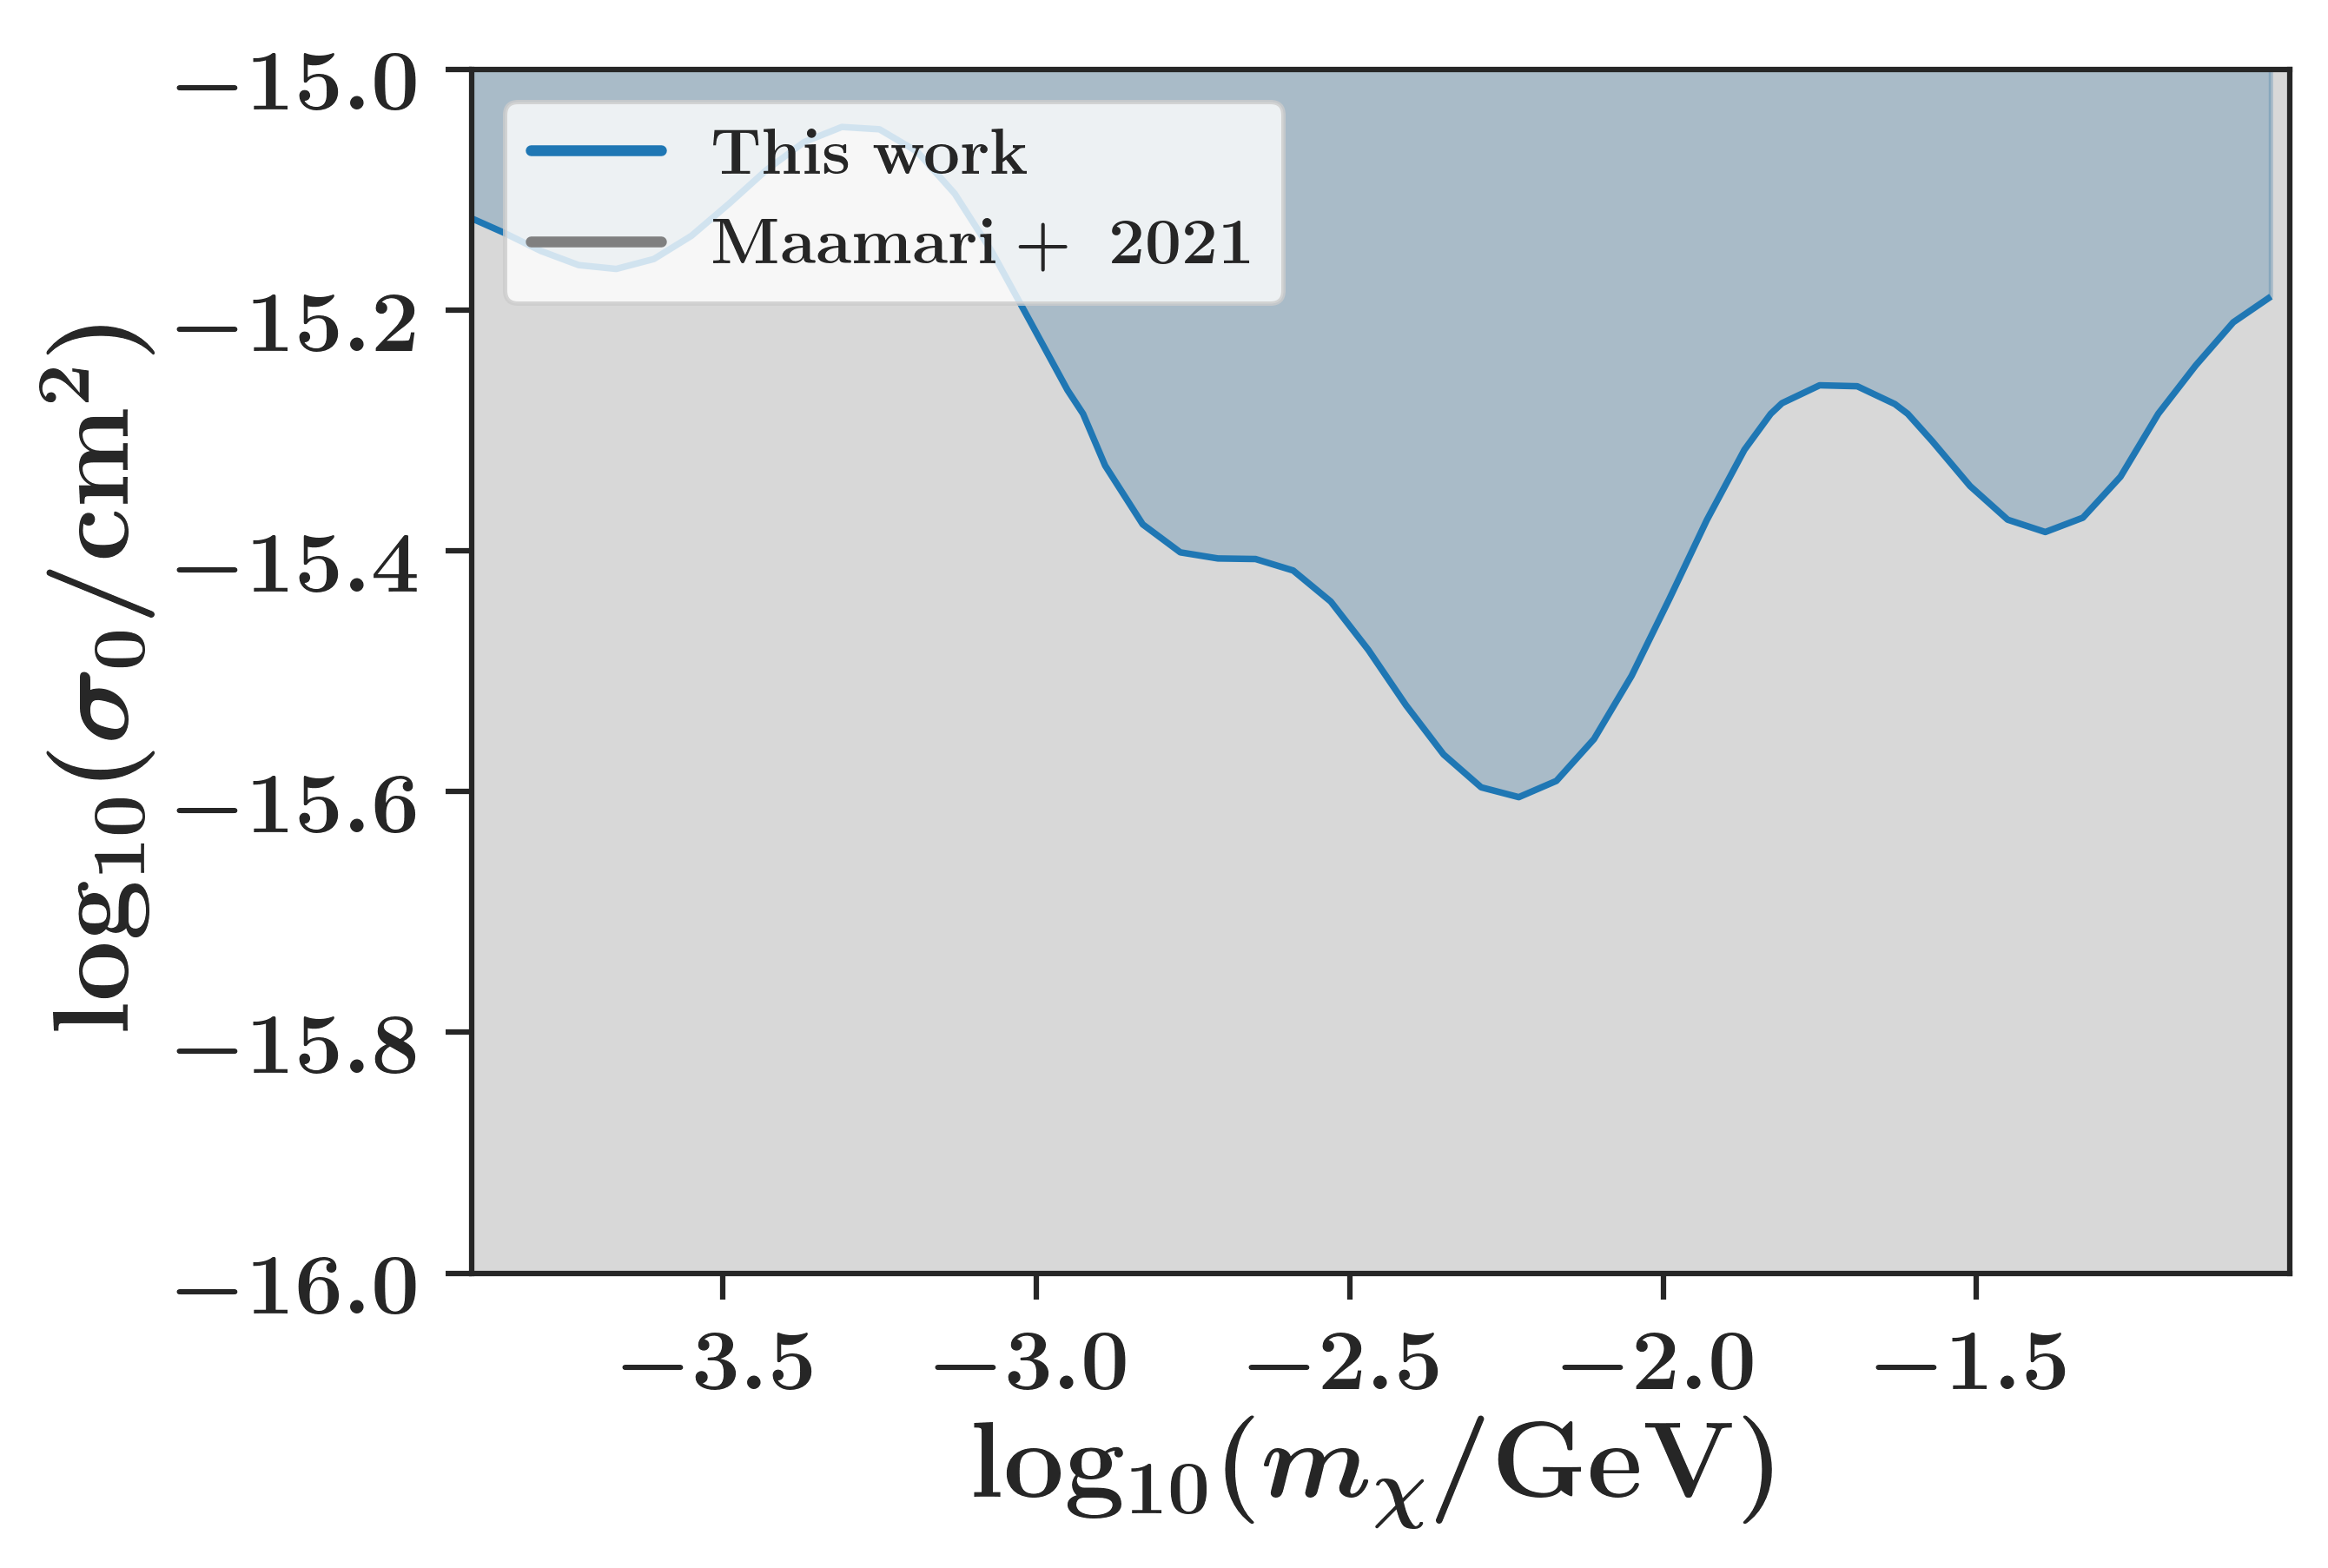

In [61]:
make_contour(mcmc_output_edd_01, -16, -15)

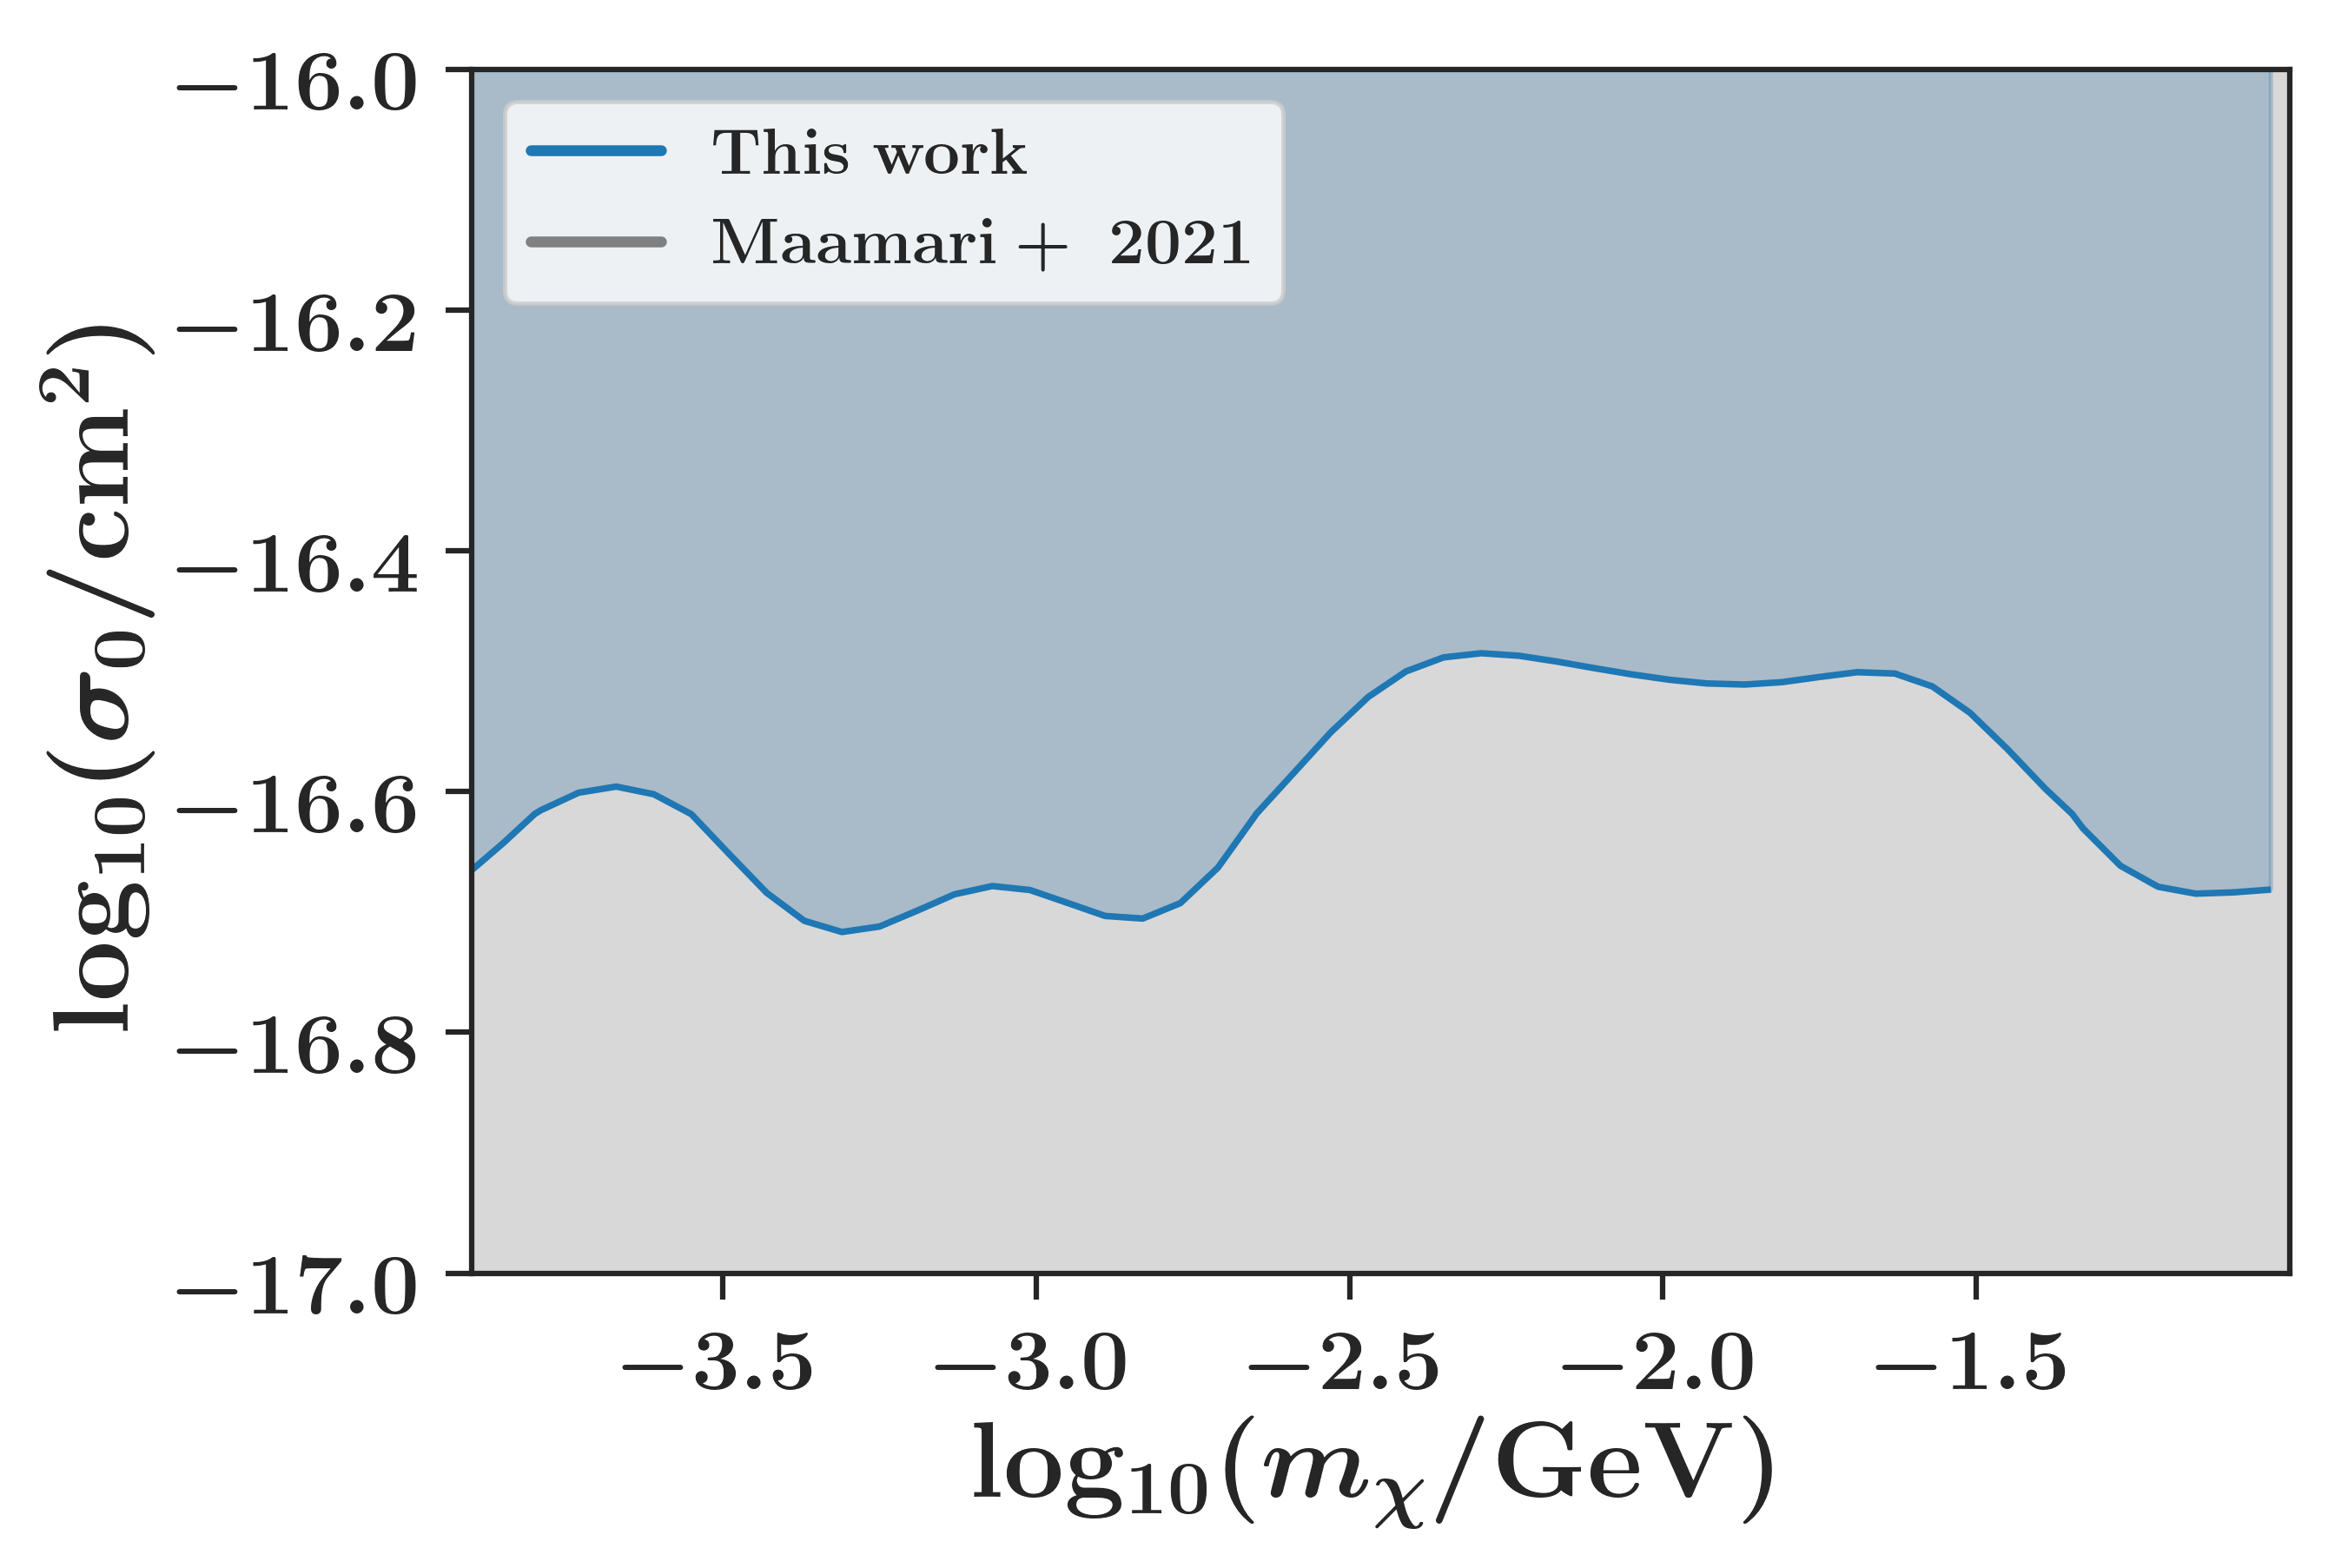

In [62]:
make_contour(mcmc_output_edd_001, -17, -16)